In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
from possessions import zone, NX, NY
from markov import matrice_transition, valeur_zones, N
from ligue import charger_ligue, actions_toutes_equipes, sequences_toutes_equipes, matrice_lissee

ev = charger_ligue(season_id=27, dossier="../data")      # long la première fois
a = actions_toutes_equipes(ev)
seq = sequences_toutes_equipes(a)
print(len(a), "actions,", len(seq), "possessions,", (seq.fin == "but").sum(), "buts")

565647 actions, 66585 possessions, 901 buts


In [2]:
t = seq.groupby("equipe").agg(
    possessions=("fin", "size"),
    buts=("fin", lambda s: (s == "but").sum()),
    longueur=("n_actions", "mean"),
)
t["taux_but"] = t.buts / t.possessions
t.sort_values("taux_but", ascending=False).round(3)

,possessions,buts,longueur,taux_but
equipe,,,,
Barcelona,3323,93,13.451,0.028
Real Madrid,3505,96,11.266,0.027
Atlético Madrid,3337,59,8.984,0.018
Athletic Club,3355,53,8.136,0.016
Celta Vigo,3404,47,9.675,0.014
Rayo Vallecano,3753,49,7.661,0.013
Eibar,3327,42,6.830,0.013
Sevilla,3333,42,7.980,0.013
Real Sociedad,3507,42,8.153,0.012


In [3]:
# 1. Toute la Liga
P_L, C_L = matrice_transition(seq)
V_L = valeur_zones(P_L)

# 2. Le Barça seul (comme à l'étape 3)
seq_B = seq[seq.equipe == "Barcelona"]
P_B, C_B = matrice_transition(seq_B)
V_B = valeur_zones(P_B)

# 3. Le Barça lissé avec l'a priori Liga
P_S = matrice_lissee(C_B, P_L, alpha=20)
V_S = valeur_zones(P_S)

for nom, x, y in [("Propre surface", 10, 40), ("Rond central", 60, 40),
                  ("Point de penalty", 108, 40), ("Devant le but", 116, 40)]:
    z = zone(x, y)
    print(f"{nom:17s} Liga {V_L[z]:6.1%}   Barça brut {V_B[z]:6.1%}   Barça lissé {V_S[z]:6.1%}")

Propre surface    Liga   0.6%   Barça brut   1.7%   Barça lissé   1.5%
Rond central      Liga   1.1%   Barça brut   2.7%   Barça lissé   2.4%
Point de penalty  Liga  15.5%   Barça brut  23.7%   Barça lissé  22.1%
Devant le but     Liga  32.2%   Barça brut  48.1%   Barça lissé  41.5%


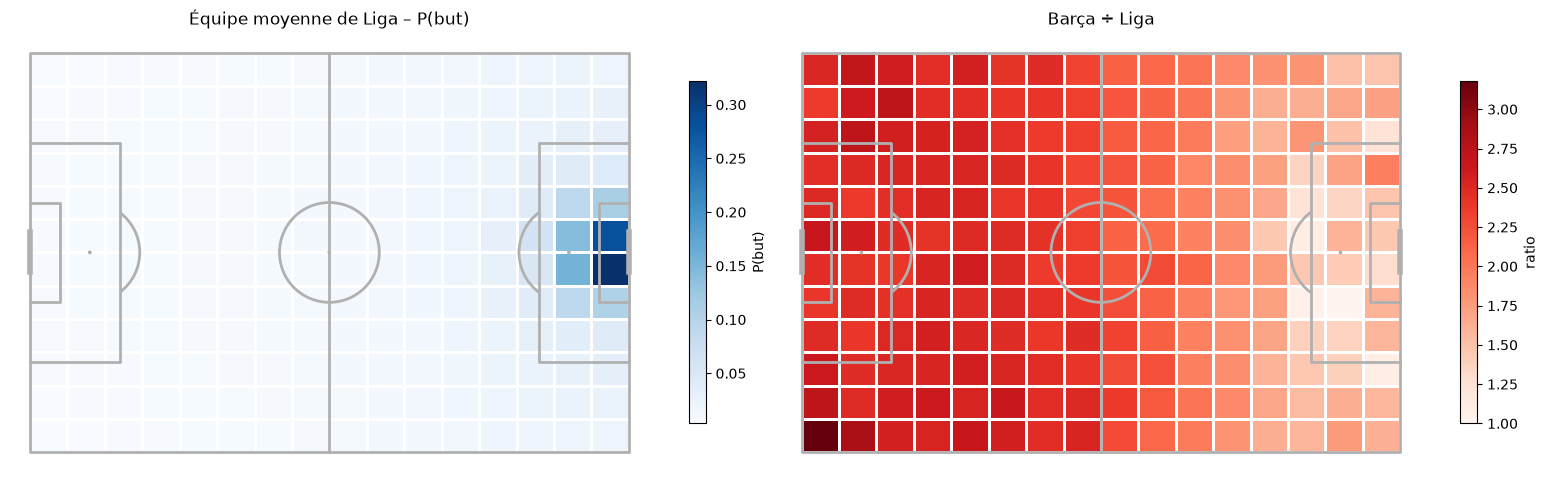

In [4]:
from mplsoccer import Pitch

pitch = Pitch(pitch_type="statsbomb", line_zorder=2)
fig, axs = pitch.draw(nrows=1, ncols=2, figsize=(16, 6))

def carte(ax, valeurs, titre, cmap, vmin=None, label=""):
    stats = pitch.bin_statistic([], [], bins=(NX, NY))
    stats["statistic"] = valeurs.reshape(NX, NY).T
    pcm = pitch.heatmap(stats, ax=ax, cmap=cmap, edgecolors="white", vmin=vmin)
    fig.colorbar(pcm, ax=ax, shrink=0.6, label=label)
    ax.set_title(titre)

carte(axs[0], V_L, "Équipe moyenne de Liga – P(but)", "Blues", label="P(but)")
carte(axs[1], V_S / V_L, "Barça ÷ Liga", "Reds", vmin=1, label="ratio")
fig.savefig("../figures/barca_vs_liga.png", dpi=150, bbox_inches="tight")

In [5]:
p_perte_L = P_L[:N, N + 1]          # probabilité de perdre le ballon à l'action suivante, Liga
p_perte_B = P_S[:N, N + 1]          # idem, Barça
poids_L = C_L[:N].sum(axis=1)       # nombre de passages par zone
poids_B = C_B[:N].sum(axis=1)

print(f"Perte par action, Liga : {np.average(p_perte_L, weights=poids_L):.1%}")
print(f"Perte par action, Barça : {np.average(p_perte_B, weights=poids_B):.1%}")

Perte par action, Liga : 11.6%
Perte par action, Barça : 7.6%


In [6]:
np.save("../data/V_L.npy", V_L)
np.save("../data/V_S.npy", V_S)